# Week 6 · Topic 4 — Apply, Lambda and Finishing Up

**Box we are building: STORE + PROCESS, the whole job**

A `lambda` is a `def` you don't bother naming, for a one-line function you are
only going to use once — usually right inside `.apply()`.

> **Already know this?** Skip to the *Topic 4 Challenge*.

---
## 1. `.apply()` runs a function on every value in a column

Start with a normal function, the way Week 3 taught it.

In [2]:
import pandas as pd

servers = pd.read_csv("servers.csv")
servers["percent"] = (servers["Used"] / servers["Total"]) * 100

def classify(percent):
    if percent >= 100:
        return "OVER LIMIT"
    elif percent >= 90:
        return "WARNING"
    else:
        return "OK"

servers["status"] = servers["percent"].apply(classify)
print(servers)

  Hostname Region  Used  Total    percent   status
0   srv_01   east    87    100  87.000000       OK
1   srv_02   east   470    500  94.000000  WARNING
2   srv_03   west   100    120  83.333333       OK
3   srv_04   west    90    200  45.000000       OK
4   srv_05  north   200    300  66.666667       OK
5   srv_06   east    45    250  18.000000       OK
6   srv_07   west    67    150  44.666667       OK
7   srv_08  north    97    360  26.944444       OK
8   srv_09   east   100    300  33.333333       OK
9   srv_10  north    70    130  53.846154       OK


### Your turn
Write your own single-argument function and `.apply()` it to the `used` column.

In [10]:
# your code here
def check(used):
    if used <= 90:
        return "Min"
    elif used >=100:
        return "Max"
    else:
        return "Med"
servers["Usage"]= servers["Used"].apply(check)
print(servers)

  Hostname Region  Used  Total    percent   status Usage
0   srv_01   east    87    100  87.000000       OK   Min
1   srv_02   east   470    500  94.000000  WARNING   Max
2   srv_03   west   100    120  83.333333       OK   Max
3   srv_04   west    90    200  45.000000       OK   Min
4   srv_05  north   200    300  66.666667       OK   Max
5   srv_06   east    45    250  18.000000       OK   Min
6   srv_07   west    67    150  44.666667       OK   Min
7   srv_08  north    97    360  26.944444       OK   Med
8   srv_09   east   100    300  33.333333       OK   Max
9   srv_10  north    70    130  53.846154       OK   Min


---
## 2. `lambda` - the same idea, written inline

`lambda parameters: expression` — that IS the whole function. Only one
expression allowed — no `if`/`elif`/`else` statements, no loops.

In [9]:
double = lambda x: x * 2
print(double(21))     # 42 - same as def double(x): return x * 2

42


```
def classify(p):                    lambda p: (
    if p >= 100:                        "OVER LIMIT" if p >= 100
        return "OVER LIMIT"             else "WARNING" if p >= 90
    elif p >= 90:                       else "OK"
        return "WARNING"             )
    else:
        return "OK"

same logic, same result - a block of statements vs one expression
```

### Your turn
Write `classify` as a lambda with a chained conditional, and check it gives the same result as the `def` version for every row.

In [12]:
# your code here
servers["status_lambda"]= servers["percent"].apply(
    lambda p: "OVER LIMIT" if p>=100 else "WARNING" if p>=90 else "OK"
)
print((servers["status"]==servers["status_lambda"]).all())

True


---
## 3. `.apply()` with a lambda, and `sort_values(key=...)`

lambda earns its place exactly here — a function small enough to write inline,
used exactly once, right where it is needed.

In [13]:
servers["status"] = servers["percent"].apply(
    lambda p: "OVER LIMIT" if p >= 100 else "WARNING" if p >= 90 else "OK"
)
print(servers.sort_values("Hostname", key=lambda col: col.str.lower()))

  Hostname Region  Used  Total    percent   status Usage status_lambda
0   srv_01   east    87    100  87.000000       OK   Min            OK
1   srv_02   east   470    500  94.000000  WARNING   Max       WARNING
2   srv_03   west   100    120  83.333333       OK   Max            OK
3   srv_04   west    90    200  45.000000       OK   Min            OK
4   srv_05  north   200    300  66.666667       OK   Max            OK
5   srv_06   east    45    250  18.000000       OK   Min            OK
6   srv_07   west    67    150  44.666667       OK   Min            OK
7   srv_08  north    97    360  26.944444       OK   Med            OK
8   srv_09   east   100    300  33.333333       OK   Max            OK
9   srv_10  north    70    130  53.846154       OK   Min            OK


### Your turn
Use `.apply()` with a lambda to add a column `region_upper` — the `region` column, in capitals.

In [16]:
# your code here
servers["region_upper"]=servers["Region"].apply(lambda r: r.upper())
print(servers)

  Hostname Region  Used  Total    percent   status Usage status_lambda  \
0   srv_01   east    87    100  87.000000       OK   Min            OK   
1   srv_02   east   470    500  94.000000  WARNING   Max       WARNING   
2   srv_03   west   100    120  83.333333       OK   Max            OK   
3   srv_04   west    90    200  45.000000       OK   Min            OK   
4   srv_05  north   200    300  66.666667       OK   Max            OK   
5   srv_06   east    45    250  18.000000       OK   Min            OK   
6   srv_07   west    67    150  44.666667       OK   Min            OK   
7   srv_08  north    97    360  26.944444       OK   Med            OK   
8   srv_09   east   100    300  33.333333       OK   Max            OK   
9   srv_10  north    70    130  53.846154       OK   Min            OK   

  region_upper  
0         EAST  
1         EAST  
2         WEST  
3         WEST  
4        NORTH  
5         EAST  
6         WEST  
7        NORTH  
8         EAST  
9        NORTH 

---
## 4. Summarising, saving, and a first chart

`describe()` for a quick overview, `.to_csv()` to save, and one chart — straight
off a DataFrame. In a notebook, calling `.plot()` shows the chart inline.

Matplotlib is building the font cache; this may take a moment.


             Used       Total    percent
count   10.000000   10.000000  10.000000
mean   132.600000  241.000000  55.279060
std    125.416816  126.968938  26.492720
min     45.000000  100.000000  18.000000
25%     74.250000  135.000000  36.166667
50%     93.500000  225.000000  49.423077
75%    100.000000  300.000000  79.166667
max    470.000000  500.000000  94.000000


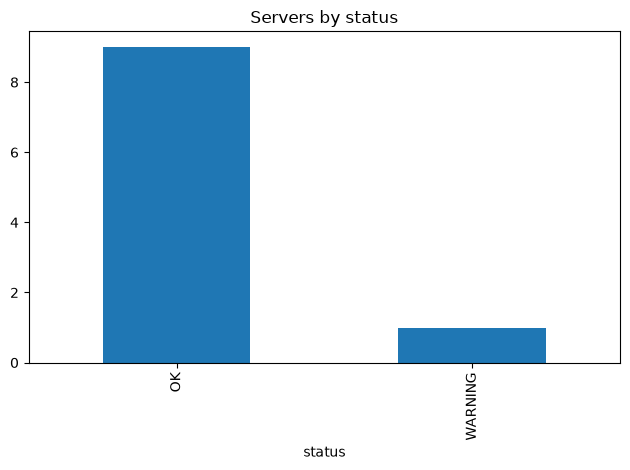

In [19]:
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

### Your turn
Make a bar chart of servers per region instead of per status.

             Used       Total    percent
count   10.000000   10.000000  10.000000
mean   132.600000  241.000000  55.279060
std    125.416816  126.968938  26.492720
min     45.000000  100.000000  18.000000
25%     74.250000  135.000000  36.166667
50%     93.500000  225.000000  49.423077
75%    100.000000  300.000000  79.166667
max    470.000000  500.000000  94.000000


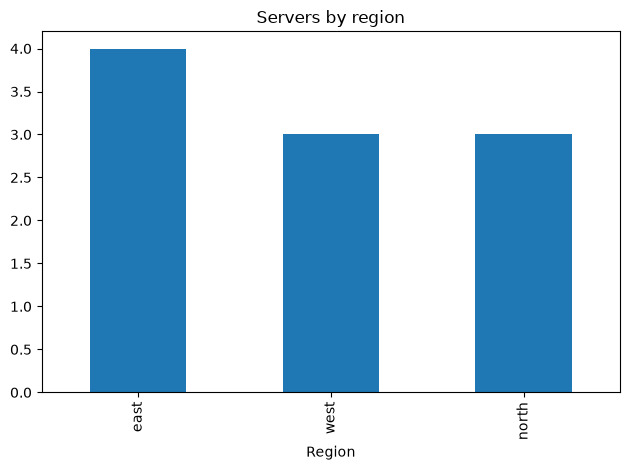

In [20]:
# your code here
import matplotlib.pyplot as plt

print(servers.describe())

servers.to_csv("servers_report.csv", index=False)

servers["Region"].value_counts().plot(kind="bar", title="Servers by region")
plt.tight_layout()
plt.show()

---
## Topic 4 Challenge

Load `servers.csv`, add `percent` and `status` (via `.apply()` with a lambda),
save the result to a new CSV, and produce one bar chart of the status counts.

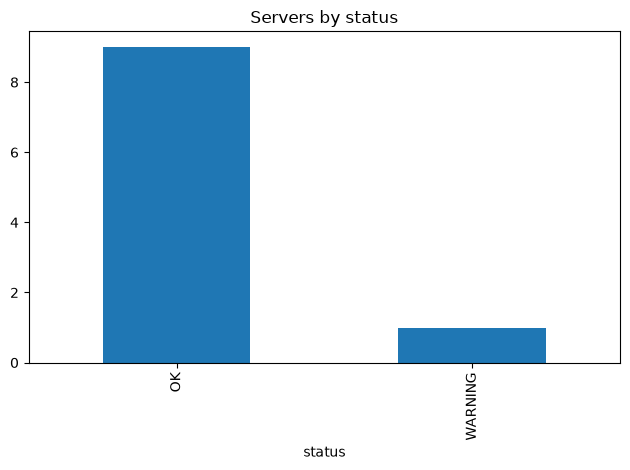

In [22]:
# your code here
import pandas as pd
import matplotlib.pyplot as plt

servers=pd.read_csv("servers.csv")
servers["percent"] = (servers["Used"] / servers["Total"]) * 100

servers["status"]= servers["percent"].apply(
    lambda p: "OVER LIMIT" if p>=100 else "WARNING" if p>=90 else "OK"
)
servers.to_csv("servers_report.csv", index=False)
servers["status"].value_counts().plot(kind="bar", title="Servers by status")
plt.tight_layout()
plt.show()

---
## Same idea, three fields

| Field | Looks like |
|---|---|
| **AI / Data Science** | `df["clean_text"] = df["text"].apply(lambda t: t.strip().lower())` |
| **Cyber Security** | `df["flag"] = df["failed"].apply(lambda n: n >= 3)` |
| **IT** | `df.sort_values("hostname", key=lambda c: c.str.lower())` |

---
## Common mistakes

| Mistake | What you see | Fix |
|---|---|---|
| a lambda with an `if` statement (not an expression) | `SyntaxError` | lambda only allows one expression — use chained `if/else`, or write a `def` |
| reusing the same lambda logic in three places | works, but repeats the logic three times | that is the sign you wanted a named function, not a lambda |
| forgetting `.apply()` and just writing `column.classify()` | `AttributeError` | `.apply(function)` runs your function on every value — the function itself is not a method on the column |
| calling `.plot()` in a plain script and seeing nothing | no chart appears | add `plt.show()` (script) — a notebook shows it automatically |

## Go deeper

`examples/01_apply_and_lambda.py` — apply, lambda syntax, chained conditionals, sort key
`examples/02_summarizing_saving_and_charting.py` — describe, to_csv, a first chart

---
## Recap

| You can now | Using |
|---|---|
| apply a function to a whole column | `column.apply(function)` |
| write a small inline function | `lambda x: expression` |
| choose lambda vs a named function | one-line, used once → lambda; reused or complex → `def` |
| get a quick overview | `.describe()` |
| save a result | `.to_csv(path, index=False)` |
| chart straight from a DataFrame | `.plot(kind=...)` |

**You now have all of CW1's toolkit.** Your mini-project this week closes it out.